# Phase 3 · Machine learning

## Data and preprocessing

This notebook starts from the dataset files in `141/` and uses the cleaning and predictors from `phase_02.ipynb`, sections 2.1 and 2.3. The original 80/20 unit-level split is reproduced before cleaning. The validation folds also keep all readings from an APU together.

In [73]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OrdinalEncoder, RobustScaler

SEED = 42
data_dir = Path("141")
readings = pd.read_csv(data_dir / "readings.csv", sep="	")
units = pd.read_csv(data_dir / "units.csv")


sensor_cols = ["current_motor", "dp_filter", "oilTemperature", "reservoir_pressure",
               "vibration_rms", "Flowmeter", "temp_bearing", "dewpointDischarge", "auxCurrent"]

In [74]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_index, test_index = next(splitter.split(readings, groups=readings['unitId']))

train_readings = readings.iloc[train_index].copy()
test_readings = readings.iloc[test_index].copy()
assert set(train_readings['unitId']).isdisjoint(test_readings['unitId'])
assert len(train_readings) + len(test_readings) == len(readings)

split_summary = pd.DataFrame([
    {'set': name, 'rows': len(frame), 'units': frame['unitId'].nunique(),
     'row_percent': 100 * len(frame) / len(readings)}
    for name, frame in [('Training', train_readings), ('Test (reserved)', test_readings)]
])
display(split_summary.round(2))

,set,rows,units,row_percent
0,Training,12097,1699,80.22
1,Test (reserved),2983,425,19.78


In [75]:
def parse_dates(values):
    parsed = pd.Series(pd.NaT, index=values.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d", "%m/%d/%Y, %H:%M:%S", "%d %b %Y", "%Y/%m/%d"]:
        parsed = parsed.fillna(pd.to_datetime(values.str.strip(), format=fmt, errors="coerce"))
    return parsed

metadata_cols = ['model_code', 'fleet_code', 'class_duty', 'commissionYear']

def prepare_readings(frame, unit_metadata):
    prepared = frame.copy()
    prepared['unitId'] = prepared['unitId'].str.extract(r'^U(\d{5})$', expand=False).astype(int)
    prepared['tsCycle'] = parse_dates(prepared['tsCycle'])
    if prepared['tsCycle'].isna().any():
        raise ValueError('Some cycle dates do not match the documented formats.')
    before = len(prepared)
    prepared = prepared.drop_duplicates()
    duplicate_rows = before - len(prepared)
    prepared = prepared.merge(unit_metadata[['unitId'] + metadata_cols], on='unitId',
                              how='left', validate='many_to_one', indicator='unit_match')
    invalid = prepared['commissionYear'].gt(prepared['tsCycle'].dt.year)
    chronology_rows = int(invalid.sum())
    prepared = prepared.loc[~invalid].copy()
    audit = {'rows_before_cleaning': before,
             'exact_duplicates_removed': duplicate_rows,
             'chronology_conflicts_removed': chronology_rows,
             'remaining_rows': len(prepared),
             'rows_without_unit_metadata': int(prepared['unit_match'].eq('left_only').sum())}
    return prepared, audit

training, cleaning_audit = prepare_readings(train_readings, units)
assert training['failure'].isin([0, 1]).all()
display(pd.Series(cleaning_audit, name='rows').to_frame())

,rows
rows_before_cleaning,12097
exact_duplicates_removed,175
chronology_conflicts_removed,247
remaining_rows,11675
rows_without_unit_metadata,115


The pipeline replaces the Phase 2 sentinel values with missing values, imputes numeric predictors with medians, applies robust scaling, and ordinal-encodes duty as light, normal, or heavy. Missing and unseen duty values use code −1. Numeric extremes are retained. Each training fold fits its own imputer and scaler. The target, unit ID, and timestamp are excluded from the model inputs.

The 11 predictors carry forward Phase 2 feature selection, which used development data. Cross-validation within that same development set is suitable for comparing candidates. An independent estimate requires the reserved set.

In [76]:
duty_aliases = {'light': 'light', 'l': 'light', '1': 'light',
                'normal': 'normal', 'n': 'normal', 'med': 'normal', '2': 'normal',
                'heavy': 'heavy', 'h': 'heavy', '3': 'heavy'}

duty_order = ['light', 'normal', 'heavy']
numeric_cols = sensor_cols + ['commissionYear']
feature_cols = numeric_cols + ['class_duty']

def normalize_predictors(frame):
    normalized = frame.copy()
    normalized['oilTemperature'] = normalized['oilTemperature'].replace(-999, np.nan)
    normalized['current_motor'] = normalized['current_motor'].replace(99, np.nan)
    duty = normalized['class_duty'].astype('string').str.strip().str.lower()
    duty = duty.replace(duty_aliases)
    normalized['class_duty'] = duty.astype(object).where(duty.notna(), np.nan)
    return normalized


cleaner = FunctionTransformer(normalize_predictors)

numeric_branch = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

duty_branch = OrdinalEncoder(categories=[duty_order + [np.nan]],
                             handle_unknown='use_encoded_value', unknown_value=-1,
                             encoded_missing_value=-1, dtype=np.int64)

column_transformer = ColumnTransformer([
    ('numeric', numeric_branch, numeric_cols),        
    ('duty', duty_branch, ['class_duty'])
], remainder='drop', verbose_feature_names_out=False)

preprocessor = Pipeline([
    ('clean', cleaner),
    ('encode_and_scale', column_transformer)
])

In [77]:
X_train = training[feature_cols]
y_train = training['failure'].astype(int)
train_groups = training['unitId']

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, groups=train_groups))
validation_rows = np.concatenate([valid_idx for _, valid_idx in cv_splits])
assert np.array_equal(np.sort(validation_rows), np.arange(len(X_train)))

fold_summary = []
for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
    fit_groups = set(train_groups.iloc[fit_idx])
    valid_groups = set(train_groups.iloc[valid_idx])
    assert fit_groups.isdisjoint(valid_groups)
    assert y_train.iloc[fit_idx].nunique() == y_train.iloc[valid_idx].nunique() == 2
    fold_summary.append({
        'Fold': fold,
        'Training units': len(fit_groups),
        'Validation units': len(valid_groups),
        'Validation readings': len(valid_idx),
        'Validation failures': int(y_train.iloc[valid_idx].sum()),
        'Validation failure rate': y_train.iloc[valid_idx].mean(),
    })
print(f"Development set: {len(y_train):,} readings, {y_train.sum():,} failures "
      f"({y_train.mean():.2%})")
display(pd.DataFrame(fold_summary).set_index('Fold').round(3))

Development set: 11,675 readings, 1,473 failures (12.62%)


,Training units,Validation units,Validation readings,Validation failures,Validation failure rate
Fold,,,,,
1,1338,330,2337,296,0.127
2,1325,343,2335,295,0.126
3,1338,330,2335,294,0.126
4,1338,330,2333,294,0.126
5,1333,335,2335,294,0.126


## 3.1 A simple classifier based on relationships in the data

### A. Implement ID3

Iterative Dichotomizer 3 (ID3) chooses the predictor that gives the largest information gain at each node. For a split on feature $A$, the information gain is the parent entropy ($H(S)$) minus the weighted mean of the child entropies ($H(S_v)$).

$$
H(S)=\sum_{c\in\{0,1\}} -p_c\log_2 p_c,
\qquad
IG(S,A)=H(S)-\sum_v \frac{|S_v|}{|S|}H(S_v).
$$

Each observed category gets its own branch, and a feature can be used once along a path. A leaf predicts its majority class. When a category has no branch at prediction time, the current node supplies its majority class and observed failure proportion. The root counts as depth 1, so a root with leaves has depth 2. 

ID3 takes categorical inputs. We discretize each numeric predictor into up to five quantile bins, keeping the encoded duty categories as they are. Quantiles are fitted inside each training fold after Phase 2 preprocessing. Tied quantiles can yield fewer distinct bins. For `commissionYear`, we keep scikit-learn's automatic merging of tied quantiles and suppress only the resulting narrow-bin warning for that column. We use equal-frequency bins to give each interval similar training support when the readings have distinct values.

In [78]:
from dataclasses import dataclass, field

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.utils.validation import check_is_fitted, validate_data


def binary_entropy(labels):
    counts = np.bincount(labels, minlength=2)
    proportions = counts[counts > 0] / len(labels)
    return -np.sum(proportions * np.log2(proportions))


@dataclass
class ID3Node:
    failure_rate: float
    feature: int | None = None
    children: dict = field(default_factory=dict)

    def depth(self):
        return 1 + max((child.depth() for child in self.children.values()), default=0)

    def leaf_count(self):
        return sum(child.leaf_count() for child in self.children.values()) or 1


class ID3Classifier(ClassifierMixin, BaseEstimator):
    def __init__(self, max_depth=None, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        X, y = validate_data(self, X, y)
        self.classes_ = np.unique(y)
        if not np.array_equal(self.classes_, [0, 1]):
            raise ValueError("ID3Classifier requires both binary labels, 0 and 1.")
        self.tree_ = self._grow(X, y.astype(int), tuple(range(X.shape[1])), level=1)
        self.depth_ = self.tree_.depth()
        self.leaf_count_ = self.tree_.leaf_count()
        return self

    def _grow(self, X, y, available, level):
        node = ID3Node(failure_rate=float(y.mean()))
        if (node.failure_rate in (0, 1)
                or not available
                or (self.max_depth is not None and level >= self.max_depth)):
            return node

        parent_entropy = binary_entropy(y)
        best_gain = 1e-12
        best_parts = {}
        for feature in available:
            values = X[:, feature]
            parts = {value: np.flatnonzero(values == value) for value in np.unique(values)}
            if len(parts) < 2 or min(map(len, parts.values())) < self.min_samples_leaf:
                continue
            weighted_entropy = sum(
                len(rows) / len(y) * binary_entropy(y[rows]) for rows in parts.values()
            )
            gain = parent_entropy - weighted_entropy
            if gain > best_gain:
                best_gain = gain
                node.feature = feature
                best_parts = parts

        if best_parts:
            remaining = tuple(feature for feature in available if feature != node.feature)
            node.children = {
                value: self._grow(X[rows], y[rows], remaining, level + 1)
                for value, rows in best_parts.items()
            }
        return node

    def _failure_rate(self, row):
        node = self.tree_
        while node.children:
            child = node.children.get(row[node.feature])
            if child is None:
                break
            node = child
        return node.failure_rate

    def predict_proba(self, X):
        check_is_fitted(self, "tree_")
        X = validate_data(self, X, reset=False)
        failure_rates = np.fromiter(map(self._failure_rate, X), dtype=float, count=len(X))
        return np.column_stack((1 - failure_rates, failure_rates))

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


# Check a perfect split and the fallback for a previously unseen category.
example = ID3Classifier().fit([[0], [0], [1], [1]], [0, 0, 1, 1])
assert example.depth_ == 2
assert example.predict([[0], [1], [2]]).tolist() == [0, 1, 0]
assert np.allclose(example.predict_proba([[2]])[0], [0.5, 0.5])

In [79]:
import warnings


class CommissionYearBinner(KBinsDiscretizer):
    def fit(self, X, y=None, sample_weight=None):
        # Tied year quantiles can collapse. Keep scikit-learn's merged bins.
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message=r"^Bins whose width are too small .* in feature 0 are removed\.",
                category=UserWarning,
                module=r"^sklearn\.preprocessing\._discretization$",
            )
            return super().fit(X, y, sample_weight=sample_weight)


def make_id3(max_depth=None, min_samples_leaf=1):
    binning = dict(n_bins=5, encode="ordinal", strategy="quantile",
                   subsample=None, quantile_method="averaged_inverted_cdf")
    year_index = numeric_cols.index("commissionYear")
    discretizer = ColumnTransformer([
        ("sensor_bins", KBinsDiscretizer(**binning), list(range(year_index))),
        ("year_bins", CommissionYearBinner(**binning), [year_index]),
    ], remainder="passthrough")
    return Pipeline([
        ("preprocess", clone(preprocessor)),
        ("discretize", discretizer),
        ("classifier", ID3Classifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf)),
    ])

### B–C. Evaluate ID3 and check for overfitting

Each of the five grouped folds evaluates the same metrics on its training and validation readings. Accuracy counts the fraction classified correctly, precision is the fraction of predicted failures that are actual failures, and recall is the fraction of actual failures detected. Class 1 is the positive class. A rule that always predicts no failure would reach about 87% accuracy on these data with zero failure recall.

We report F1, the harmonic mean of failure precision and recall, and average precision (AP), which summarizes precision and recall across score thresholds. We diagnose overfitting by looking for a training–validation gap, especially in AP, alongside the number of leaves. To reduce variance, we compare an unrestricted tree with trees limited to two through five levels and at least 30 training readings per child. We select the shallowest constrained tree whose mean validation AP is within one standard error of the best constrained mean. This is a simplicity rule for model selection. Fold standard errors are descriptive because training folds overlap.

In [80]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score,
)

metric_names = ["Accuracy", "Precision", "Recall", "F1", "AP"]


def classification_metrics(y_true, y_pred, failure_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AP": average_precision_score(y_true, failure_score),
    }


def evaluate_folds(name, pipeline):
    results = []
    for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
        fitted = clone(pipeline).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        model = fitted.named_steps["classifier"]
        for split, indices in [("Training", fit_idx), ("Validation", valid_idx)]:
            X_fold, y_fold = X_train.iloc[indices], y_train.iloc[indices]
            results.append({
                "Model": name,
                "Fold": fold,
                "Split": split,
                **classification_metrics(y_fold, fitted.predict(X_fold),
                                         fitted.predict_proba(X_fold)[:, 1]),
                "Depth (levels)": getattr(model, "depth_", np.nan),
                "Leaves": getattr(model, "leaf_count_", np.nan),
            })
    return pd.DataFrame(results)


unrestricted = "ID3 unrestricted"
id3_models = {unrestricted: make_id3()}
id3_models.update({f"ID3 {levels} levels": make_id3(max_depth=levels, min_samples_leaf=30)
                   for levels in range(2, 6)})
id3_cv = pd.concat([evaluate_folds(name, model) for name, model in id3_models.items()],
                   ignore_index=True)

id3_cv_means = id3_cv.groupby(["Model", "Split"], sort=False)[metric_names].mean()
id3_cv_ap = id3_cv_means["AP"].unstack("Split").rename(
    columns={"Training": "Train AP", "Validation": "Validation AP"})
id3_cv_ap["AP gap"] = id3_cv_ap["Train AP"] - id3_cv_ap["Validation AP"]
id3_validation = id3_cv[id3_cv["Split"].eq("Validation")]
id3_cv_ap["Validation AP SE"] = id3_validation.groupby("Model")["AP"].sem()
id3_cv_ap["Mean leaves"] = id3_validation.groupby("Model")["Leaves"].mean()

constrained = id3_cv_ap.drop(index=unrestricted)
best_constrained = constrained["Validation AP"].idxmax()
cutoff = (constrained.at[best_constrained, "Validation AP"]
          - constrained.at[best_constrained, "Validation AP SE"])
selected_id3 = constrained.index[constrained["Validation AP"].ge(cutoff)][0]
assert id3_validation.loc[id3_validation["Model"].eq(selected_id3),
                          "Depth (levels)"].min() >= 2

display(id3_cv_ap.round(3))
display(id3_cv_means.loc[[unrestricted, selected_id3]].round(3))
print(f"Selected {selected_id3} for comparison. Validation AP cutoff = {cutoff:.3f}.")

Split,Train AP,Validation AP,AP gap,Validation AP SE,Mean leaves
Model,,,,,
ID3 unrestricted,1.000,0.151,0.849,0.005,3104.4
ID3 2 levels,0.171,0.168,0.003,0.005,4.8
ID3 3 levels,0.219,0.211,0.008,0.004,22.6
ID3 4 levels,0.278,0.217,0.062,0.006,111.0
ID3 5 levels,0.281,0.216,0.066,0.006,133.0


Accuracy  Precision  Recall     F1     AP
Model            Split                                                
ID3 unrestricted Training       1.000      1.000   0.999  0.999  1.000
                 Validation     0.798      0.213   0.221  0.216  0.151
ID3 3 levels     Training       0.874      0.000   0.000  0.000  0.219
                 Validation     0.874      0.000   0.000  0.000  0.211

Selected ID3 3 levels for comparison. Validation AP cutoff = 0.211.


The unrestricted tree has about 3,104 leaves per fold. Its training AP is 1.000, but validation AP falls to 0.151. The training accuracy is nearly 100% and the validation accuracy falls to 79.8%. Both gaps indicate overfitting.

The selected tree has three levels, including the root, with at least 30 training readings per child. It has about 23 leaves per fold. Its training and validation AP are 0.219 and 0.211, respectively. The smaller gap and higher validation AP support the depth and leaf-size limits. Its majority-class rule detects no failures in validation, so its 87.4% accuracy matches the always-no-failure baseline. Section 3.2 evaluates whether a lower threshold on its leaf failure proportions makes the scores more useful.

## 3.2 Training and evaluating machine learning classifiers

### A–C. Compare three classifiers

We compare ID3 with two scikit-learn pipelines, CART decision trees and logistic regression, on the same grouped validation folds. The CART decision tree uses Gini impurity and binary splits on numeric thresholds. A preset three-split depth limit keeps the learned rules readable. Logistic regression uses an L2 penalty with the default regularization strength. Its linear log-odds serve as a non-tree reference.

Both scikit-learn models use the same Phase 2 preprocessing as ID3. They use continuous numeric values without ID3's quantile binning. We use the usual class decision for each estimator and keep the observed class proportions.

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

cart_name = "CART decision tree"
logistic_name = "Logistic regression"
models = {
    selected_id3: id3_models[selected_id3],
    cart_name: Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    ]),
    logistic_name: Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
}

model_cv = pd.concat([
    id3_cv.loc[id3_cv["Model"].eq(selected_id3)],
    evaluate_folds(cart_name, models[cart_name]),
    evaluate_folds(logistic_name, models[logistic_name]),
], ignore_index=True)
validation_metrics = model_cv.loc[model_cv["Split"].eq("Validation")]
validation_summary = validation_metrics.groupby("Model", sort=False)[metric_names].agg(["mean", "std"])
display(validation_summary.round(3))

Accuracy        Precision        Recall            F1  \
                        mean    std      mean    std   mean    std   mean   
Model                                                                       
ID3 3 levels           0.874  0.000     0.000  0.000  0.000  0.000  0.000   
CART decision tree     0.878  0.003     0.552  0.041  0.140  0.088  0.212   
Logistic regression    0.873  0.004     0.510  0.187  0.049  0.019  0.088   

                               AP         
                       std   mean    std  
Model                                     
ID3 3 levels         0.000  0.211  0.010  
CART decision tree   0.128  0.256  0.028  
Logistic regression  0.031  0.326  0.026

#### Choosing a threshold using development data

The validation scores above use the models' default class decisions. We choose the threshold that maximizes failure F1 over the out-of-fold scores, breaking ties in favor of the higher threshold. F1 balances precision and recall for this comparison. The threshold selection uses the development folds, so the reserved APUs provide the evaluation of the resulting rules.

In [82]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

alert_thresholds = {}
for name, model in models.items():
    out_of_fold = cross_val_predict(
        model, X_train, y_train, cv=cv_splits, method="predict_proba"
    )[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_train, out_of_fold)
    precision, recall = precision[:-1], recall[:-1]
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(precision), where=(precision + recall) > 0)
    best_index = np.flatnonzero(f1 == f1.max())[-1]
    alert_thresholds[name] = float(thresholds[best_index])

display(pd.Series(alert_thresholds, name="Failure alert threshold").to_frame().round(4))

,Failure alert threshold
ID3 3 levels,0.1667
CART decision tree,0.1769
Logistic regression,0.2066


### D. Visualize the decision rules

Each node shows the rule applied to a preprocessed reading. Follow the left branch when the condition is true. Continuous thresholds are in robust-scaled units. Duty codes are −1 for missing or unseen, 0 for light, 1 for normal, and 2 for heavy. The node's class is its majority training label. The root uses `dp_filter`. Later splits use `dp_filter`, `class_duty`, and `current_motor`.

Final ID3 depth: 3 levels, including the root. Leaves: 25.


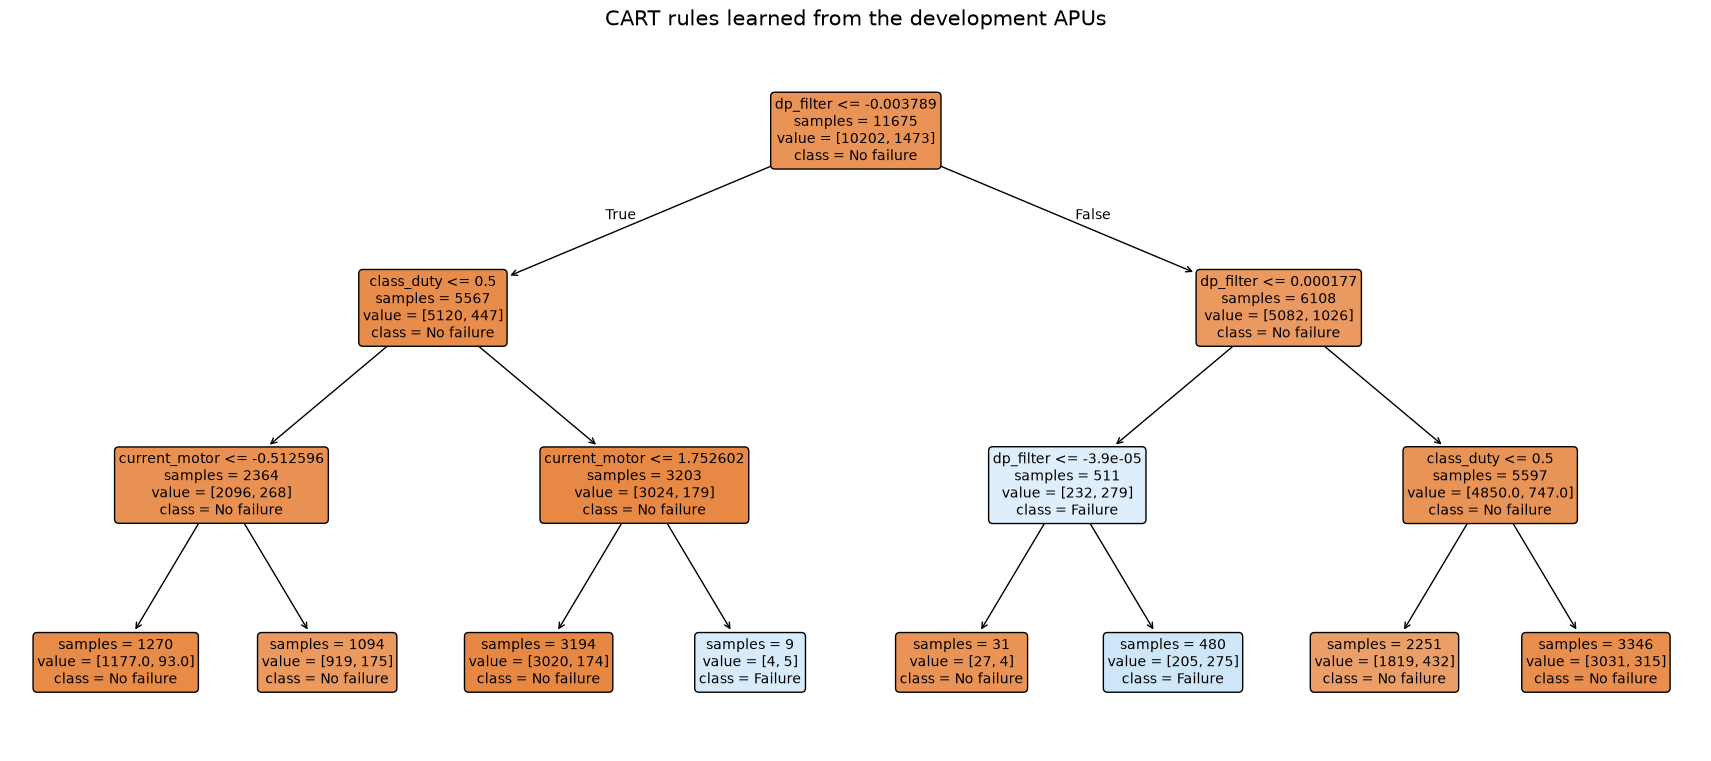

In [83]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

fitted_models = {name: clone(model).fit(X_train, y_train) for name, model in models.items()}
fitted_id3 = fitted_models[selected_id3].named_steps["classifier"]
assert fitted_id3.depth_ >= 2
print(f"Final ID3 depth: {fitted_id3.depth_} levels, including the root. "
      f"Leaves: {fitted_id3.leaf_count_}.")

fig, ax = plt.subplots(figsize=(17, 7.5), layout="constrained")
plot_tree(fitted_models[cart_name].named_steps["classifier"],
          feature_names=feature_cols, class_names=["No failure", "Failure"],
          filled=True, rounded=True, impurity=False, precision=6, fontsize=10, ax=ax)
ax.set_title("CART rules learned from the development APUs", fontsize=15, pad=12)
display(fig)
plt.close(fig)

### E. Evaluate on the reserved APUs

We now apply the fixed Phase 2 row-cleaning rules to the reserved partition and score the three fitted pipelines. The first table uses the default class decisions. The second uses the alert thresholds chosen on development data. AP depends on the ranking of failure scores and is identical across the two tables. All imputation, scaling, binning, and model parameters come from the development data. Each metric pools readings across the held-out APUs. These scores measure classification of the recorded `failure` label on unseen units. The experiment does not measure how far ahead an alert could predict a future failure.

In [84]:
test, test_audit = prepare_readings(test_readings, units)
assert set(training["unitId"]).isdisjoint(test["unitId"])
assert test["failure"].isin([0, 1]).all()
X_test = test[feature_cols]
y_test = test["failure"].astype(int)

holdout_rows = []
for name, fitted in fitted_models.items():
    failure_score = fitted.predict_proba(X_test)[:, 1]
    decisions = {
        "Default": fitted.predict(X_test),
        "Alert threshold": (failure_score >= alert_thresholds[name]).astype(int),
    }
    for rule, prediction in decisions.items():
        tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
        assert tn + fp + fn + tp == len(y_test)
        holdout_rows.append({
            "Model": name,
            "Rule": rule,
            **classification_metrics(y_test, prediction, failure_score),
            "False positives": fp,
            "Missed failures": fn,
            "Detected failures": tp,
        })

holdout_results = pd.DataFrame(holdout_rows).set_index(["Rule", "Model"])
print(f"Holdout: {len(y_test):,} eligible readings from {test['unitId'].nunique():,} APUs. "
      f"{y_test.sum():,} failures ({y_test.mean():.2%}).")
print(f"Always predicting no failure: accuracy {1 - y_test.mean():.3f}, recall 0.")
display(holdout_results.loc["Default"].round(3))
display(holdout_results.loc["Alert threshold"].round(3))

Holdout: 2,902 eligible readings from 421 APUs. 356 failures (12.27%).
Always predicting no failure: accuracy 0.877, recall 0.


,Accuracy,Precision,Recall,F1,AP,False positives,Missed failures,Detected failures
Model,,,,,,,,
ID3 3 levels,0.877,0.000,0.000,0.000,0.181,0,356,0
CART decision tree,0.879,0.529,0.154,0.239,0.247,49,301,55
Logistic regression,0.878,0.522,0.067,0.119,0.311,22,332,24


,Accuracy,Precision,Recall,F1,AP,False positives,Missed failures,Detected failures
Model,,,,,,,,
ID3 3 levels,0.749,0.194,0.331,0.245,0.181,491,238,118
CART decision tree,0.763,0.247,0.455,0.320,0.247,495,194,162
Logistic regression,0.820,0.326,0.441,0.375,0.311,324,199,157


All three accuracies are close to the 87.7% majority baseline. ID3 flags zero failures, CART detects 55 of 356 failures, and logistic regression detects 24. Precision is reported as zero when a rule issues no positive predictions.

For development-selected thresholds. ID3 detects 118 failures (33.1% recall), with 19.4% precision. CART detects 162 (45.5% recall) with 495 false alerts. Logistic regression detects 157 (44.1% recall) with 324 false alerts, reaching 32.6% precision. It has the highest holdout F1 (0.375) and AP (0.311) of the configurations. CART finds five more failures at the cost of 171 additional false alerts.

## Experiment s vazenymi failures nizsie

In [85]:
# Logistic regression with class weights, using the existing grouped folds
from sklearn.metrics import roc_curve

weight_options = {
    "Unweighted": None,
    "Failure weight 3x": {0: 1, 1: 3},
    "Balanced": "balanced",
}
weighted_models = {
    name: clone(models[logistic_name]).set_params(classifier__class_weight=weight)
    for name, weight in weight_options.items()
}

weight_fold_ap = {}
weight_thresholds = {}
for name, model in weighted_models.items():
    scores = cross_val_predict(
        model, X_train, y_train, cv=cv_splits, method="predict_proba"
    )[:, 1]
    weight_fold_ap[name] = [
        average_precision_score(y_train.iloc[valid_idx], scores[valid_idx])
        for _, valid_idx in cv_splits
    ]
    precision, recall, thresholds = precision_recall_curve(y_train, scores)
    precision, recall = precision[:-1], recall[:-1]
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(precision), where=(precision + recall) > 0)
    best_index = np.flatnonzero(f1 == f1.max())[-1]
    weight_thresholds[name] = float(thresholds[best_index])

weight_cv_ap = pd.DataFrame(weight_fold_ap, index=pd.Index(range(1, 6), name="Fold"))
weight_cv_summary = weight_cv_ap.agg(["mean", "std"]).T
assert np.isclose(weight_thresholds["Unweighted"], alert_thresholds[logistic_name])
assert np.isclose(weight_cv_summary.loc["Unweighted", "mean"],
                  validation_summary.loc[logistic_name, ("AP", "mean")])
print("Validation average precision by fold")
display(weight_cv_ap.round(4))
display(weight_cv_summary.rename(columns={"mean": "Mean AP", "std": "SD across folds"}).round(4))

Validation average precision by fold


,Unweighted,Failure weight 3x,Balanced
Fold,,,
1,0.3576,0.3568,0.3568
2,0.3007,0.2992,0.2985
3,0.3509,0.3474,0.3431
4,0.3038,0.3063,0.3076
5,0.3189,0.3173,0.3172


,Mean AP,SD across folds
Unweighted,0.3264,0.0265
Failure weight 3x,0.3254,0.0255
Balanced,0.3246,0.0245


In [86]:
# Holdout results at the development-selected thresholds and an equal false-alert rate.
# The fixed-rate comparison interpolates the ROC curves for ranking comparison.
comparison_fpr = 0.10
weight_holdout_rows = []
for name, model in weighted_models.items():
    fitted = clone(model).fit(X_train, y_train)
    scores = fitted.predict_proba(X_test)[:, 1]
    threshold = weight_thresholds[name]
    alerts = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, alerts, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(y_test)
    fpr, tpr, _ = roc_curve(y_test, scores, drop_intermediate=False)
    weight_holdout_rows.append({
        "Weights": name,
        "Threshold": threshold,
        **classification_metrics(y_test, alerts, scores),
        "False alerts": fp,
        "Detected failures": tp,
        "Recall at 10% FPR (interpolated)": np.interp(comparison_fpr, fpr, tpr),
    })

weight_holdout_results = pd.DataFrame(weight_holdout_rows).set_index("Weights")
for metric in metric_names:
    assert np.isclose(weight_holdout_results.loc["Unweighted", metric],
                      holdout_results.loc[("Alert threshold", logistic_name), metric])
print("Holdout results using thresholds chosen on development folds")
display(weight_holdout_results.round(4))

Holdout results using thresholds chosen on development folds


,Threshold,Accuracy,Precision,Recall,F1,AP,False alerts,Detected failures,Recall at 10% FPR (interpolated)
Weights,,,,,,,,,
Unweighted,0.2066,0.8198,0.3264,0.4410,0.3751,0.3111,324,157,0.3933
Failure weight 3x,0.4327,0.8208,0.3320,0.4551,0.3839,0.3105,326,162,0.4017
Balanced,0.6442,0.8267,0.3385,0.4326,0.3798,0.3105,301,154,0.4045


## 3.3A Hyperparameter tuning

The best performing model in this stage is CART decision tree. In the next steps we will focus on tuning the model's hyperparameters with the goal of achieving best results.
We use grid search, which tries every combination from the given parameters.

In [87]:
from sklearn.model_selection import GridSearchCV

cart_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(random_state=SEED)),
])

param_grid = {
    "classifier__max_depth": [2, 3, 4, 5, 6, 8, None],
    "classifier__min_samples_leaf": [10, 30, 50, 100, 300],
    "classifier__ccp_alpha": [0.0, 1e-4, 1e-3],
    "classifier__class_weight": [None, "balanced", {0: 1, 1: 3}],
}

search = GridSearchCV(
    cart_pipeline, param_grid,
    cv=cv_splits,                    
    scoring="average_precision",
    return_train_score=True,         
    refit=False,                     
    n_jobs=-1,
)
search.fit(X_train, y_train)
print(f"{len(search.cv_results_['params'])} settings x {len(cv_splits)} folds evaluated")

Python(18490) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(18491) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(18492) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(18493) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(18494) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(18495) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(18496) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(18497) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


315 settings x 5 folds evaluated


In [88]:
cv_res = pd.DataFrame(search.cv_results_)
fold_cols = [f"split{i}_test_score" for i in range(len(cv_splits))]

tuning = cv_res[[c for c in cv_res.columns if c.startswith("param_classifier__")]]
tuning = tuning.rename(columns=lambda c: c.replace("param_classifier__", ""))
tuning["train_AP"] = cv_res["mean_train_score"]
tuning["val_AP"] = cv_res["mean_test_score"]
tuning["val_SE"] = cv_res[fold_cols].sem(axis=1)          # standard error across folds
tuning["gap"] = tuning["train_AP"] - tuning["val_AP"]      # overfitting indicator
tuning["depth_rank"] = tuning["max_depth"].map(lambda d: 99 if pd.isna(d) else d)

display(tuning.sort_values("val_AP", ascending=False).head(10).round(4))

# Mean validation AP by depth (best setting of the other parameters for each depth)
by_depth = (tuning.groupby("depth_rank")[["train_AP", "val_AP"]]
            .max().rename(index={99: "None"}))
display(by_depth.round(4))

,ccp_alpha,class_weight,max_depth,min_samples_leaf,train_AP,val_AP,val_SE,gap,depth_rank
136,0.0001,None,None,30,0.5078,0.3356,0.0133,0.1722,99
61,0.0000,balanced,8,30,0.4835,0.3329,0.0116,0.1506,8
137,0.0001,None,None,50,0.4511,0.3315,0.0118,0.1196,99
66,0.0000,balanced,None,30,0.5399,0.3315,0.0128,0.2085,99
32,0.0000,None,None,50,0.4635,0.3312,0.0123,0.1323,99
31,0.0000,None,None,30,0.5254,0.3311,0.0149,0.1944,99
131,0.0001,None,8,30,0.4690,0.3305,0.0105,0.1385,8
96,0.0000,"{0: 1, 1: 3}",8,30,0.4882,0.3304,0.0116,0.1579,8
206,0.0001,"{0: 1, 1: 3}",None,30,0.5314,0.3296,0.0133,0.2018,99
27,0.0000,None,8,50,0.4445,0.3294,0.0116,0.1151,8


,train_AP,val_AP
depth_rank,,
2,0.2248,0.2141
3,0.2760,0.2667
4,0.3228,0.2988
5,0.3717,0.3115
6,0.4225,0.3200
8,0.5443,0.3329
None,0.7207,0.3356


In [89]:
best = tuning["val_AP"].idxmax()
cutoff = tuning.at[best, "val_AP"] - tuning.at[best, "val_SE"]
candidates = tuning[tuning["val_AP"] >= cutoff]

# Simplest candidate: shallowest tree, then larger leaves, then stronger pruning.
chosen = candidates.sort_values(
    ["depth_rank", "min_samples_leaf", "ccp_alpha", "val_AP"],
    ascending=[True, False, False, False]).index[0]
best_params = search.cv_results_["params"][chosen]

print(f"Best mean validation AP: {tuning.at[best, 'val_AP']:.4f} "
      f"(SE {tuning.at[best, 'val_SE']:.4f}); cutoff {cutoff:.4f}; "
      f"{len(candidates)} settings are within one SE.")
print("Chosen parameters:", best_params)
display(tuning.loc[[best, chosen]].round(4).rename(index={best: "best", chosen: "chosen"}))

Best mean validation AP: 0.3356 (SE 0.0133); cutoff 0.3223; 16 settings are within one SE.
Chosen parameters: {'classifier__ccp_alpha': 0.0001, 'classifier__class_weight': None, 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 50}


,ccp_alpha,class_weight,max_depth,min_samples_leaf,train_AP,val_AP,val_SE,gap,depth_rank
best,0.0001,None,None,30,0.5078,0.3356,0.0133,0.1722,99
chosen,0.0001,None,8,50,0.4378,0.3292,0.0114,0.1086,8


In [90]:
tuned_cart = clone(cart_pipeline).set_params(**best_params).fit(X_train, y_train)
tree = tuned_cart.named_steps["classifier"]

comparison = pd.DataFrame({
    "Validation AP": {
        "Always predict by prevalence (baseline)": y_train.mean(),
        "CART depth 3, default (3.2)": validation_summary.loc[cart_name, ("AP", "mean")],
        "CART tuned (3.3A)": tuning.at[chosen, "val_AP"],
    }
})
display(comparison.round(4))
print(f"Tuned tree: depth {tree.get_depth()}, {tree.get_n_leaves()} leaves, "
      f"train AP {tuning.at[chosen, 'train_AP']:.4f}, "
      f"validation AP {tuning.at[chosen, 'val_AP']:.4f}, gap {tuning.at[chosen, 'gap']:.4f}")

,Validation AP
Always predict by prevalence (baseline),0.1262
"CART depth 3, default (3.2)",0.2563
CART tuned (3.3A),0.3292


Tuned tree: depth 8, 59 leaves, train AP 0.4378, validation AP 0.3292, gap 0.1086


In [91]:
cart_name = "CART decision tree"
logistic_name = "Logistic regression"
tuned_models = {
    selected_id3: id3_models[selected_id3],
    "CART original": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    ]),
    "CART tuned": tuned_cart,
    logistic_name: Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
    ])
}

tuned_models = {name: clone(model).fit(X_train, y_train) for name, model in tuned_models.items()}

holdout_rows = []
for name, fitted in tuned_models.items():
    failure_score = fitted.predict_proba(X_test)[:, 1]
    decisions = {
        "Default": fitted.predict(X_test)}
    for rule, prediction in decisions.items():
        tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
        assert tn + fp + fn + tp == len(y_test)
        holdout_rows.append({
            "Model": name,
            "Rule": rule,
            **classification_metrics(y_test, prediction, failure_score),
            "False positives": fp,
            "Missed failures": fn,
            "Detected failures": tp,
        })

holdout_results = pd.DataFrame(holdout_rows).set_index(["Rule", "Model"])
print(f"Always predicting no failure: accuracy {1 - y_test.mean():.3f}, recall 0.")
display(holdout_results.loc["Default"].round(3))

Always predicting no failure: accuracy 0.877, recall 0.


,Accuracy,Precision,Recall,F1,AP,False positives,Missed failures,Detected failures
Model,,,,,,,,
ID3 3 levels,0.877,0.000,0.000,0.000,0.181,0,356,0
CART original,0.879,0.529,0.154,0.239,0.247,49,301,55
CART tuned,0.877,0.496,0.180,0.264,0.313,65,292,64
Logistic regression,0.878,0.522,0.067,0.119,0.311,22,332,24


Even after tuning the CART decision tree we get lower precision around 50% while getting better other features. This result is not ideal so we try another model - Gradient Boosting, which can capture non-linear patterns in our data. We use randomized search with 60 random iterations for the hyperparameter tuning, otherwise the number of all possible combinations would be too large because Gradient Boosting uses more parameters than CART.

In [92]:
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

gb_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("classifier", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED)),
])

gb_space = {
    "classifier__learning_rate": [0.02, 0.05, 0.1],
    "classifier__max_iter": [100, 200, 400, 800],
    "classifier__max_depth": [3, 4, 6, None],
    "classifier__max_leaf_nodes": [8, 15, 31],
    "classifier__min_samples_leaf": [20, 50, 100, 200],
    "classifier__l2_regularization": [0.0, 1.0, 10.0],
}

gb_search = RandomizedSearchCV(
    gb_pipeline, gb_space, n_iter=60, cv=cv_splits, scoring="average_precision",
    return_train_score=True, refit=False, random_state=SEED, n_jobs=-1)
gb_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__l2_regularization': [0.0, 1.0, ...], 'classifier__learning_rate': [0.02, 0.05, ...], 'classifier__max_depth': [3, 4, ...], 'classifier__max_iter': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",60
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are 

Again we select the best combination of parameters that has the smallest gap - smallest difference between train and validation AP which shows that the model does not overfit, while still getting results which are near the standart error from the best validation AP.

In [93]:
res = pd.DataFrame(gb_search.cv_results_)
fold_cols = [f"split{i}_test_score" for i in range(len(cv_splits))]

gb_tuning = res[[c for c in res.columns if c.startswith("param_classifier__")]]
gb_tuning = gb_tuning.rename(columns=lambda c: c.replace("param_classifier__", ""))
gb_tuning["train_AP"] = res["mean_train_score"]
gb_tuning["val_AP"] = res["mean_test_score"]
gb_tuning["val_SE"] = res[fold_cols].sem(axis=1)
gb_tuning["gap"] = gb_tuning["train_AP"] - gb_tuning["val_AP"]
display(gb_tuning.sort_values("val_AP", ascending=False).head(10).round(4))

best = gb_tuning["val_AP"].idxmax()
cutoff = gb_tuning.at[best, "val_AP"] - gb_tuning.at[best, "val_SE"]
candidates = gb_tuning[gb_tuning["val_AP"] >= cutoff]
chosen = candidates["gap"].idxmin()                    
gb_best_params = gb_search.cv_results_["params"][chosen]

print(f"Best validation AP {gb_tuning.at[best, 'val_AP']:.4f} (SE {gb_tuning.at[best, 'val_SE']:.4f}); "
      f"{len(candidates)} settings within one SE.")
print("Chosen:", gb_best_params)
display(gb_tuning.loc[[best, chosen]].round(4).rename(index={best: "best AP", chosen: "chosen"}))

,min_samples_leaf,max_leaf_nodes,max_iter,max_depth,learning_rate,l2_regularization,train_AP,val_AP,val_SE,gap
35,50,8,100,6,0.10,10.0,0.6009,0.4921,0.0098,0.1088
28,50,15,800,3,0.02,10.0,0.6044,0.4919,0.0094,0.1125
47,20,8,400,4,0.05,10.0,0.6390,0.4900,0.0110,0.1490
8,20,15,100,3,0.10,1.0,0.6099,0.4882,0.0112,0.1217
18,100,8,800,3,0.02,10.0,0.5985,0.4880,0.0089,0.1105
16,50,8,100,None,0.10,0.0,0.6325,0.4877,0.0112,0.1448
54,50,8,100,6,0.10,0.0,0.6305,0.4863,0.0106,0.1443
25,50,8,200,4,0.05,1.0,0.6201,0.4859,0.0104,0.1342
53,200,15,200,3,0.10,1.0,0.6113,0.4839,0.0093,0.1273
29,100,8,400,3,0.02,1.0,0.5841,0.4838,0.0095,0.1003


Best validation AP 0.4921 (SE 0.0098); 13 settings within one SE.
Chosen: {'classifier__min_samples_leaf': 100, 'classifier__max_leaf_nodes': 8, 'classifier__max_iter': 400, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.02, 'classifier__l2_regularization': 1.0}


,min_samples_leaf,max_leaf_nodes,max_iter,max_depth,learning_rate,l2_regularization,train_AP,val_AP,val_SE,gap
best AP,50,8,100,6,0.10,10.0,0.6009,0.4921,0.0098,0.1088
chosen,100,8,400,3,0.02,1.0,0.5841,0.4838,0.0095,0.1003


The top 10 settings are all around 0.60 AP, so no single setting matters much. This is a good signal of stability, because the result does not depend on a lucky combination. Next we compare the original gradient boosting with the tuned version and also random forest.

In [94]:
tuned_gb = clone(gb_pipeline).set_params(**gb_best_params).fit(X_train, y_train)

def cv_report(model):
    r = cross_validate(model, X_train, y_train, cv=cv_splits, scoring="average_precision",
                       return_train_score=True, n_jobs=-1)
    v = r["test_score"]
    return {"train AP": r["train_score"].mean(), "validation AP": v.mean(),
            "SE": v.std(ddof=1) / np.sqrt(len(v)),
            "gap": r["train_score"].mean() - v.mean()}

models = {
    "Gradient boosting, defaults": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", HistGradientBoostingClassifier(
            learning_rate=0.05, max_depth=4, max_iter=300, l2_regularization=1.0,
            early_stopping=True, random_state=SEED))]),
    "Gradient boosting, tuned": tuned_gb,
    "Random forest": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=10, max_features="sqrt",
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]),
}
display(pd.DataFrame({name: cv_report(m) for name, m in models.items()}).T.round(4))

,train AP,validation AP,SE,gap
"Gradient boosting, defaults",0.6460,0.4773,0.0086,0.1687
"Gradient boosting, tuned",0.5841,0.4838,0.0095,0.1003
Random forest,0.9049,0.4376,0.0123,0.4673


In [95]:
cart_name = "CART decision tree"
tuned_models = {
    selected_id3: id3_models[selected_id3],
    "CART original": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    ]),
    "CART tuned": tuned_cart,
    "Gradient Boosting":Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", HistGradientBoostingClassifier(
            learning_rate=0.05, max_depth=4, max_iter=300, l2_regularization=1.0,
            early_stopping=True, random_state=SEED))]),
    "Gradient Boosting tuned":tuned_gb,
}

tuned_models = {name: clone(model).fit(X_train, y_train) for name, model in tuned_models.items()}

holdout_rows = []
for name, fitted in tuned_models.items():
    failure_score = fitted.predict_proba(X_test)[:, 1]
    decisions = {
        "Default": fitted.predict(X_test)}
    for rule, prediction in decisions.items():
        tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
        assert tn + fp + fn + tp == len(y_test)
        holdout_rows.append({
            "Model": name,
            "Rule": rule,
            **classification_metrics(y_test, prediction, failure_score),
            "False positives": fp,
            "Missed failures": fn,
            "Detected failures": tp,
        })

holdout_results = pd.DataFrame(holdout_rows).set_index(["Rule", "Model"])
print(f"Always predicting no failure: accuracy {1 - y_test.mean():.3f}, recall 0.")
display(holdout_results.loc["Default"].round(3))

Always predicting no failure: accuracy 0.877, recall 0.


,Accuracy,Precision,Recall,F1,AP,False positives,Missed failures,Detected failures
Model,,,,,,,,
ID3 3 levels,0.877,0.000,0.000,0.000,0.181,0,356,0
CART original,0.879,0.529,0.154,0.239,0.247,49,301,55
CART tuned,0.877,0.496,0.180,0.264,0.313,65,292,64
Gradient Boosting,0.890,0.716,0.177,0.284,0.456,25,293,63
Gradient Boosting tuned,0.891,0.870,0.132,0.229,0.458,7,309,47


## 3.3 D Proof of not overfitting

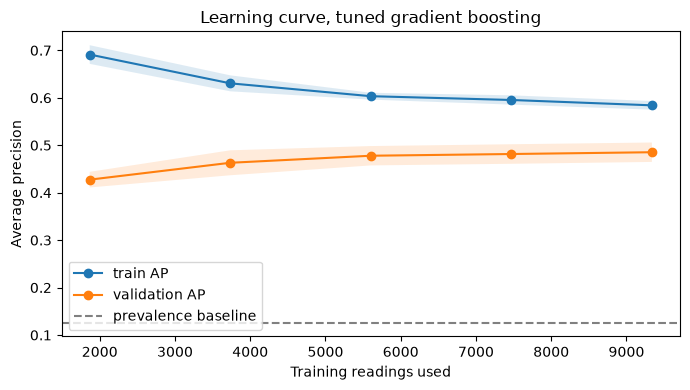

In [96]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, validation_curve, cross_validate

sizes, tr, va = learning_curve(
    tuned_gb, X_train, y_train, cv=cv_splits, scoring="average_precision",
    train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1, random_state=SEED)

fig, ax = plt.subplots(figsize=(7, 4))
for scores, label in [(tr, "train AP"), (va, "validation AP")]:
    m, s = scores.mean(axis=1), scores.std(axis=1, ddof=1)
    ax.plot(sizes, m, marker="o", label=label)
    ax.fill_between(sizes, m - s, m + s, alpha=0.15)
ax.axhline(y_train.mean(), color="gray", linestyle="--", label="prevalence baseline")
ax.set_xlabel("Training readings used"); ax.set_ylabel("Average precision")
ax.set_title("Learning curve, tuned gradient boosting"); ax.legend(); plt.tight_layout(); plt.show()

The gap between the 2 curves is not too big which proves that the model does not overfit otherwise it would perform much better on the training set. It is needed to note that both of the curves are flatlining which could indicate that the model is not finding the underlining pattern. This would be more likely if the performance was lower.

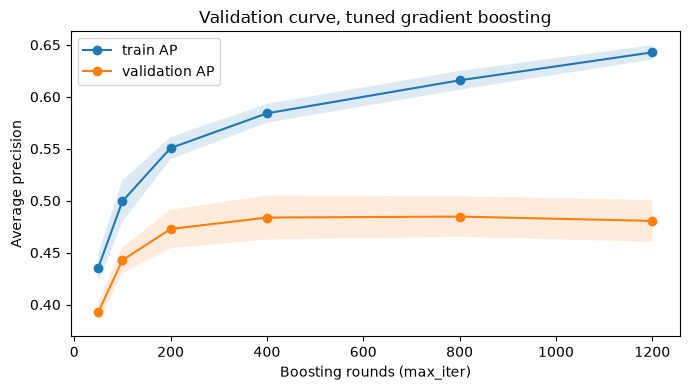

In [97]:
rounds = [50, 100, 200, 400, 800, 1200]
tr_v, va_v = validation_curve(
    tuned_gb, X_train, y_train, param_name="classifier__max_iter", param_range=rounds,
    cv=cv_splits, scoring="average_precision", n_jobs=-1)

fig, ax = plt.subplots(figsize=(7, 4))
for scores, label in [(tr_v, "train AP"), (va_v, "validation AP")]:
    m, s = scores.mean(axis=1), scores.std(axis=1, ddof=1)
    ax.plot(rounds, m, marker="o", label=label)
    ax.fill_between(rounds, m - s, m + s, alpha=0.15)
ax.set_xlabel("Boosting rounds (max_iter)"); ax.set_ylabel("Average precision")
ax.set_title("Validation curve, tuned gradient boosting"); ax.legend(); plt.tight_layout(); plt.show()


Here the gap between training and validation is getting bigger, however overfitting would have the validation curve decrease after some time, which does not happen. This can 

In [98]:
r = cross_validate(tuned_gb, X_train, y_train, cv=cv_splits, scoring="average_precision",
                   return_train_score=True, n_jobs=-1)
folds = pd.DataFrame({"train AP": r["train_score"], "validation AP": r["test_score"]},
                     index=[f"fold {i}" for i in range(1, len(cv_splits) + 1)])
folds["gap"] = folds["train AP"] - folds["validation AP"]
display(folds.round(4))
print(f"Validation AP: mean {folds['validation AP'].mean():.4f}, "
      f"min {folds['validation AP'].min():.4f}, max {folds['validation AP'].max():.4f}")

,train AP,validation AP,gap
fold 1,0.5703,0.5146,0.0556
fold 2,0.5801,0.4834,0.0967
fold 3,0.5873,0.4807,0.1065
fold 4,0.5912,0.4853,0.1060
fold 5,0.5917,0.4548,0.1369


Validation AP: mean 0.4838, min 0.4548, max 0.5146
